<div style="background: linear-gradient(135deg, #fdfbfb 0%, #ebedee 100%); border-radius: 10px; border-left: 6px solid #ff9900; box-shadow: 0 3px 6px rgba(0,0,0,0.06); width: 100%; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; overflow: hidden;">
  <table style="border: none; width: 100%; margin: 0; border-collapse: collapse; background: transparent;">
    <tr style="border: none; background: transparent;">
      <td style="border: none; width: 100px; text-align: center; vertical-align: middle; padding: 14px 0 14px 15px; background: transparent;">
        <img src="https://github.com/sansalamanca/shining-path_DP700/raw/main/data/logo%20libro.jpg" width="85" style="border-radius: 8px; display: block; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
      </td>
      <td style="border: none; vertical-align: middle; padding: 14px 15px; background: transparent;">
        <div style="color: #555555; font-size: 13px; font-weight: 500; margin-bottom: 2px;">Excerpt from the Amazon book</div>
        <div style="font-family: 'Arial Black', Impact, sans-serif; font-size: 18px; font-weight: 900; text-transform: uppercase; letter-spacing: 1.5px; color: #111111; margin: 6px 0 10px 0; line-height: 1.2;">THE SHINING PATH TO DATA ENGINEER CERTIFICATE</div>
        <div>
          <a href="https://www.amazon.com" target="_blank" style="color: #b12704; text-decoration: none; font-weight: 600; font-size: 13px; display: inline-block;">🛒 Buy on Amazon &rarr;</a>
        </div>
      </td>
    </tr>
  </table>
</div>

**For this notebook to work, you must execute ALL the cells in the order in which they appear.**

In [1]:
# 1. getting files from repository
!git clone https://github.com/sansalamanca/shining-path_DP700.git

Cloning into 'shining-path_DP700'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 71 (delta 28), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 565.39 KiB | 2.91 MiB/s, done.
Resolving deltas: 100% (28/28), done.


In [2]:
#2.  Initiating Spark session
from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("Session 8 Plotting") \
    .getOrCreate()


# **View the DF you are working on**

In [3]:
# 3. reading parquet file using the right path
df = spark.read.format("parquet").load("shining-path_DP700/data/orders_parquet")

# 4. display it
df.show(5)               # In Fabric use display(df)

+----------------+--------------------+----------+--------------+--------------------+--------------------+--------+---------+--------+
|SalesOrderNumber|SalesOrderLineNumber| OrderDate|  CustomerName|               Email|                Item|Quantity|UnitPrice|     Tax|
+----------------+--------------------+----------+--------------+--------------------+--------------------+--------+---------+--------+
|         SO43701|                   1|2019-07-01|   Christy Zhu|christy12@adventu...|Mountain-100 Silv...|       1|  3399.99|271.9992|
|         SO43704|                   1|2019-07-01|    Julio Ruiz|julio1@adventure-...|Mountain-100 Blac...|       1|  3374.99|269.9992|
|         SO43705|                   1|2019-07-01|     Curtis Lu|curtis9@adventure...|Mountain-100 Silv...|       1|  3399.99|271.9992|
|         SO43700|                   1|2019-07-01|  Ruben Prasad|ruben10@adventure...|  Road-650 Black, 62|       1| 699.0982| 55.9279|
|         SO43703|                   1|2019-07-0

# **Group the data to obtain the total units sold per product**

In [5]:
from pyspark.sql import functions as F

# Group the data to obtain the total units sold per product (item)
productSales = (
    df.groupBy("Item")
    .agg(F.sum("Quantity").alias("TotalSold"))
    .orderBy(F.col("TotalSold").desc()))
productSales.show()   # In Fabric use:  display(productSales)

+--------------------+---------+
|                Item|TotalSold|
+--------------------+---------+
|    Road-150 Red, 62|      197|
|    Road-150 Red, 48|      179|
|    Road-150 Red, 56|      167|
|    Road-150 Red, 44|      157|
|    Road-150 Red, 52|      155|
|Mountain-100 Silv...|       39|
|Mountain-100 Blac...|       35|
|Mountain-100 Silv...|       28|
|Mountain-100 Blac...|       25|
|Mountain-100 Blac...|       24|
|Mountain-100 Blac...|       23|
|Mountain-100 Silv...|       21|
|  Road-650 Black, 52|       20|
|  Road-650 Black, 60|       15|
|  Road-650 Black, 62|       15|
|  Road-650 Black, 44|       14|
|Mountain-100 Silv...|       14|
|    Road-650 Red, 48|       13|
|    Road-650 Red, 60|       13|
|  Road-650 Black, 58|       11|
+--------------------+---------+
only showing top 20 rows


## **Display chart**

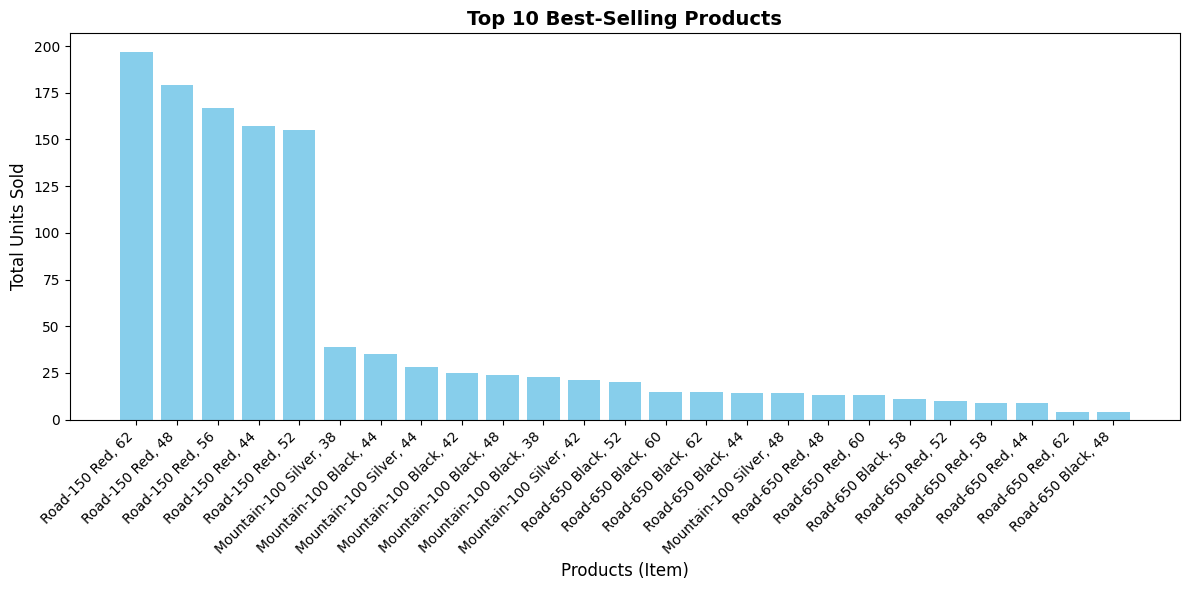

In [6]:
from matplotlib import pyplot as plt

# 1. Convert the result into a Pandas DataFrame so that Matplotlib can read it
df_pandas = productSales.toPandas()

# 2. Create the bar chart using Matplotlib
plt.figure(figsize=(12, 6))
plt.bar(df_pandas["Item"], df_pandas["TotalSold"], color="skyblue")

# 3. Customize labels and design
plt.xlabel("Products (Item)", fontsize=12)
plt.ylabel("Total Units Sold", fontsize=12)
plt.title(
    "Top 10 Best-Selling Products", fontsize=14, fontweight="bold"
)
plt.xticks(
    rotation=45, ha="right"
)  # Rotate the product names so they don't overlap.
plt.tight_layout()

# 4. Display Graphic
plt.show()     # <-- This command also works in Fabric.

## **Use the Seaborn library (sns.barplot)**

/tmp/ipykernel_2536/1725014018.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="Item", y="TotalSold", data=df_pandas, palette="Blues_r")


<Figure size 640x480 with 0 Axes>

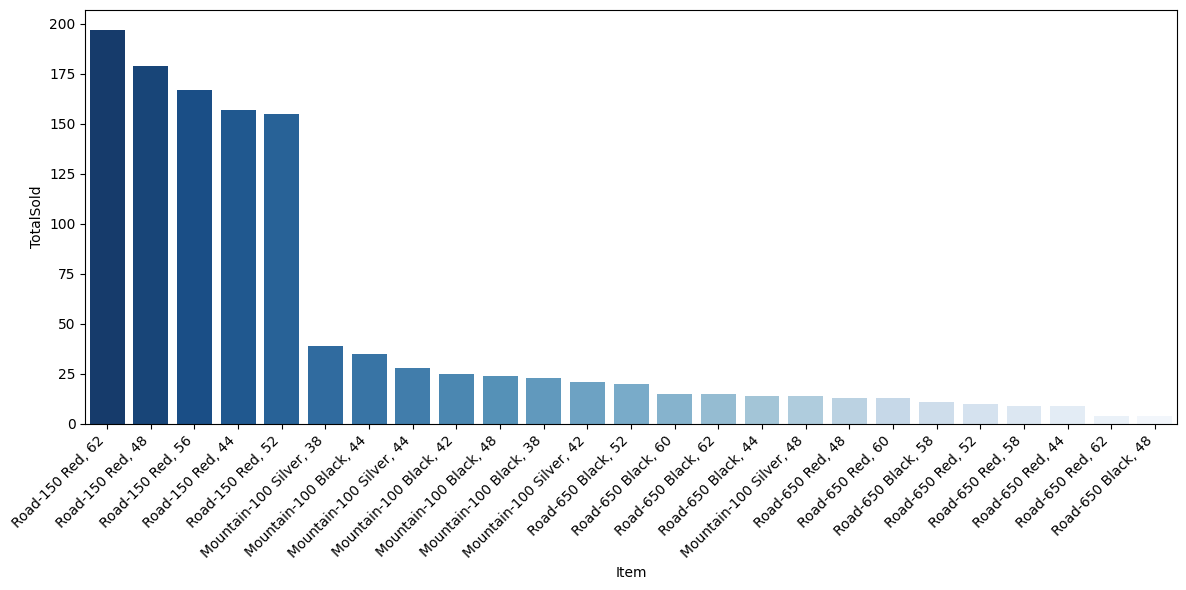

In [7]:
import seaborn as sns
import warnings
import matplotlib.pyplot as plt

# Clear the plot area
plt.clf()

# Suppress FutureWarning from seaborn
warnings.filterwarnings('ignore', message='use_inf_as_na', category=FutureWarning)

# Create a bar chart using the correct DataFrame (df_pandas) and its columns
plt.figure(figsize=(12, 6))
ax = sns.barplot(x="Item", y="TotalSold", data=df_pandas, palette="Blues_r")

# Rotate labels for readability
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
